# Arriva bus timetables: building a clean journey dataset from Bus Open Data

This notebook turns Arriva's published timetable files (TransXChange XML, from the Department for Transport's [Bus Open Data Service](https://data.bus-data.dft.gov.uk/)) into one clean table with a row per scheduled journey, and looks at how service frequency varies by route, direction, day type and hour.

**What the data is, and is not.** These files hold *scheduled* departures. They say when a bus is timetabled to leave, not how many people ride it, so everything below is about service supply, not passenger demand.

The reusable code lives in `bods_pipeline.py`; this notebook imports it and shows the results.

In [1]:
import os, sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

sys.path.insert(0, str(Path.cwd().parent))
import bods_pipeline as bp

# Full dataset in data/raw if present, otherwise the small sample in data/sample.
repo = Path.cwd().parent
raw = repo / "data" / "raw"
DATA_DIR = Path(os.environ.get("BODS_DATA", raw if any(raw.glob("*.xml")) else repo / "data" / "sample"))
print("Reading from:", DATA_DIR.name)

Reading from: raw


## 1. Read every file and clean

Each file is parsed with `xml.etree`. A malformed file is skipped rather than stopping the run, and exact duplicate rows are removed.

In [2]:
df = bp.clean_dataset(bp.build_master_dataset(DATA_DIR))
df.head()

Found 384 XML files in data/raw


Extracted 11503 journeys across 97 routes
Removed 38 exact duplicate rows
Routes: 61 linear, 36 circular


,route_line,direction,departure_time,operating_days,source_file,hour,day_type,route_type
0,10B,outbound,06:11:00,"Monday,Tuesday,Wednesday,Thursday,Friday",AMSY_10G_AMSYPC000114157610B_20260830_-_240923...,6,Mon-Fri,linear
1,10B,outbound,06:19:00,"Monday,Tuesday,Wednesday,Thursday,Friday",AMSY_10G_AMSYPC000114157610B_20260830_-_240923...,6,Mon-Fri,linear
2,10B,outbound,06:27:00,"Monday,Tuesday,Wednesday,Thursday,Friday",AMSY_10G_AMSYPC000114157610B_20260830_-_240923...,6,Mon-Fri,linear
3,10B,outbound,06:33:00,"Monday,Tuesday,Wednesday,Thursday,Friday",AMSY_10G_AMSYPC000114157610B_20260830_-_240923...,6,Mon-Fri,linear
4,10B,outbound,06:43:00,"Monday,Tuesday,Wednesday,Thursday,Friday",AMSY_10G_AMSYPC000114157610B_20260830_-_240923...,6,Mon-Fri,linear


## 2. The network at a glance

In [3]:
summary = bp.route_summary(df)
print(f"{len(df):,} scheduled journeys, {df['route_line'].nunique()} routes")
summary.head(10)

11,465 scheduled journeys, 97 routes


day_type,Mon-Fri,Saturday,Sunday,total
route_line,,,,
86A,230,214,125,569
82,192,173,121,486
437,174,159,110,443
79,203,143,97,443
15,174,122,90,386
14,143,119,91,353
10B,166,108,66,340
75,132,106,76,314
410,112,113,68,293


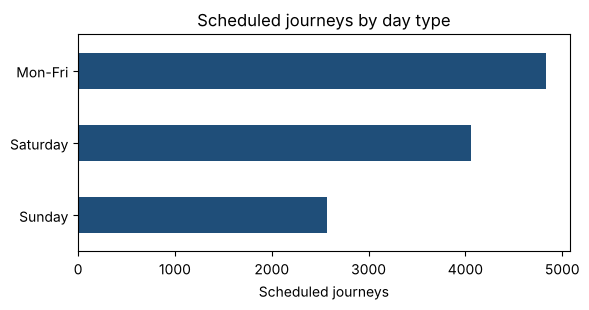

In [4]:
by_day = df.groupby("day_type").size().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(6, 3.2))
by_day.plot.barh(ax=ax, color="#1F4E79")
ax.invert_yaxis()
ax.set_xlabel("Scheduled journeys")
ax.set_ylabel("")
ax.set_title("Scheduled journeys by day type")
fig.tight_layout()
plt.show()

## 3. Checking the numbers against Arriva's own timetable

My first count for Route 78 looked wrong (54 "daily" journeys). Checking it against Arriva's published timetable showed the 54 were really 27 outbound plus 27 inbound, which I had not separated. That led to three fixes, each now built into the code:

1. **Route name.** The files are named like `K78`, but the route passengers see is `78`. The real name is the `<LineName>` inside the file.
2. **Direction.** It comes from each journey's `JourneyPattern`, not from the filename.
3. **Operating days.** They usually sit on the `Service`, not on each journey, and some files use shorthand such as `MondayToFriday`.

In [5]:
r78 = df[(df["route_line"] == "78") & (df["day_type"] == "Mon-Fri")]
counts = r78.groupby("direction").size()
print(counts.to_string())
assert counts.to_dict() == {"inbound": 27, "outbound": 27}, "Route 78 no longer matches the published timetable"
print("\nMatches the published Arriva timetable: 27 outbound, 27 inbound.")

direction
inbound     27
outbound    27

Matches the published Arriva timetable: 27 outbound, 27 inbound.


## 4. Service frequency through the day: Route 78

In [6]:
route = "78"
profile = bp.hourly_profile(df, route)
profile

day_type  Mon-Fri          Saturday           Sunday         
direction inbound outbound  inbound outbound inbound outbound
hour                                                         
5               0        2        0        0       0        0
6               2        2        0        1       0        0
7               2        2        1        1       0        1
8               1        2        1        1       1        1
9               2        2        1        1       1        1
10              2        2        1        1       1        1
11              2        2        1        1       1        1
12              2        2        1        1       1        1
13              2        2        1        1       1        1
14              2        2        1        1       1        1
15              2        1        1        1       1        1
16              2        2        1        1       1        1
17              2        2        1        1       1        0
18              2        2        1        0       0        0
19              2        0        0        0       0        0

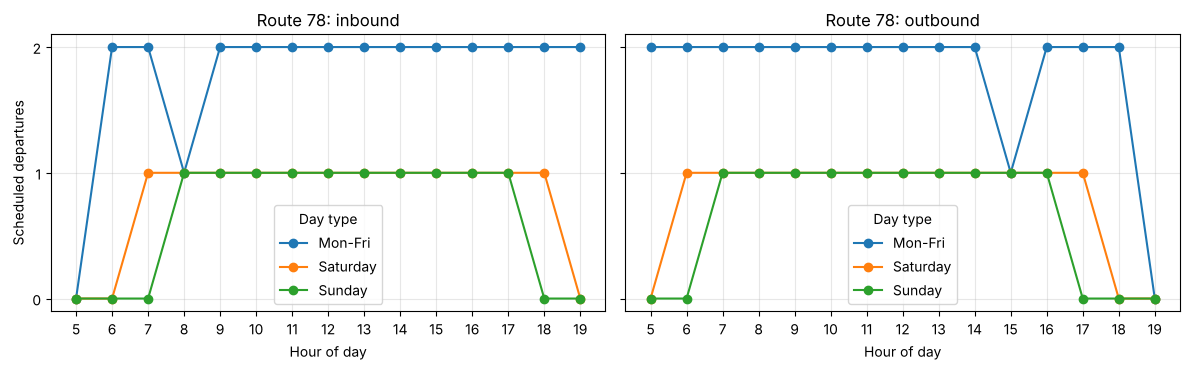

In [7]:
r = df[df["route_line"] == route]
directions = sorted(r["direction"].unique())
hours = range(int(r["hour"].min()), int(r["hour"].max()) + 1)
fig, axes = plt.subplots(1, len(directions), figsize=(6 * len(directions), 3.8), sharey=True, squeeze=False)
for ax, d in zip(axes[0], directions):
    for dtype, grp in r[r["direction"] == d].groupby("day_type"):
        c = grp.groupby("hour").size().reindex(hours, fill_value=0)
        ax.plot(c.index, c.values, marker="o", label=dtype)
    ax.set_title(f"Route {route}: {d}")
    ax.set_xlabel("Hour of day")
    ax.set_xticks(list(hours))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.3)
    ax.legend(title="Day type")
axes[0][0].set_ylabel("Scheduled departures")
fig.tight_layout()
plt.show()

On weekdays Route 78 runs about two buses an hour each way through the day, starting with outbound departures in the 05:00 hour and ending with inbound departures in the 19:00 hour. Saturdays and Sundays run at about one bus an hour each way.

## 5. Circular and linear routes

A circular route starts and ends at the same place, so it only ever has outbound journeys. The pipeline flags these so "journeys per direction" is not misread.

In [8]:
df.groupby("route_type")["route_line"].nunique()

route_type
circular    36
linear      61
Name: route_line, dtype: int64

## Limitations and next steps

- The data is **scheduled** service. It cannot show passenger numbers, delays or cancellations.
- Day types come from each service's operating profile. Bank holidays, school-term variations and date ranges are not yet modelled.
- **Next stage:** a simple simulator that tests a proposed timetable against historical demand, which would need a demand source such as ticketing or occupancy data.

*Contains public sector information licensed under the Open Government Licence v3.0. Source: Bus Open Data Service, Department for Transport.*